<a href="https://colab.research.google.com/github/DANIEL-VELASCO/proyecto-decision-transformer/blob/main/00_prueba_viabilidad_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00 · Prueba de viabilidad en Google Colab
**Proyecto:** Control robótico a partir de datos registrados: Decision Transformer frente a métodos clásicos de RL offline
**Autor:** Daniel Sebastian Velasco Munar · Aprendizaje Profundo 202630 · PUJ

Este notebook **no es el experimento final**. Su objetivo es comprobar, de punta a punta y con presupuestos de
entrenamiento pequeños, que todo lo que plantea la propuesta funciona en Colab:

1. Instalación de Minari, MuJoCo, d3rlpy y Hugging Face Transformers.
2. Descarga del dataset `mujoco/hopper/medium-v0` y recuperación del simulador.
3. Entrenamiento corto de los 4 modelos: Random Forest (BC), MLP (BC), IQL y Decision Transformer.
4. Evaluación en el simulador y cálculo del puntaje normalizado.
5. Medición de tiempos para estimar el costo de los experimentos completos.

> **Antes de ejecutar:** `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4`.

## 1. Instalación

In [1]:
# Se instala por partes: si un paquete falla, el error queda a la vista y no frena a los demás.
# No se fija la versión de mujoco porque las versiones viejas no tienen instalador para el Python actual de Colab.
!python --version
!pip install "gymnasium[mujoco]" mujoco
!pip install "minari[all]"
!pip install d3rlpy transformers imageio
!pip list 2>/dev/null | grep -iE "^(minari|gymnasium|mujoco|d3rlpy|transformers) "

Python 3.13.16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 90.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 95.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 104.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mujoco]
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 721.7/721.7 kB 25.1 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 958.1/958.1 kB 21.5 MB/s  0:00:00
  Created wheel for gym: filename=gym-0.26.2-py3-none-any.whl size=827726 sha256=2eb24594b5fc9f9644d5335d7fe80a295383de90e1134a3291c6eb37b3f2a2b8
  Stored in directory: /root/.cache/pip/wheels/1d/34/c6/856a1e1eff47d8f18545c833b6138ae1e9f53c7de9bcc5f31d
Successfully built gym
  Attempting uninstall: gymnasium
    Found existing installation: gymnasium 1.4.0
    Uninstalling gymnasium-1.4.0:
      Successfully 

In [3]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    os.environ["MUJOCO_GL"] = "egl"      # render sin pantalla en Colab

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
import gymnasium as gym, minari, mujoco, d3rlpy, transformers, imageio
from sklearn.ensemble import RandomForestRegressor
from transformers import DecisionTransformerConfig, DecisionTransformerModel
from IPython.display import Image, display

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
for lib in (minari, gym, mujoco, d3rlpy, transformers, torch):
    print(f"{lib.__name__:>13}: {lib.__version__}")

Dispositivo: cuda (Tesla T4)
       minari: 0.5.4
    gymnasium: 1.0.0
       mujoco: 4.0.1
       d3rlpy: 2.8.1
 transformers: 5.22.1
        torch: 2.14.1+cu130


## 2. Configuración
Los presupuestos de entrenamiento son **deliberadamente pequeños**. En los experimentos finales se aumentarán
(por ejemplo, ~100k pasos para el Decision Transformer, como en el artículo original).

In [4]:
DATASET_ID    = "mujoco/hopper/medium-v0"
EXPERT_ID     = "mujoco/hopper/expert-v0"   # solo para la referencia del puntaje normalizado
SEED          = 42

# Decision Transformer
K             = 20        # longitud del contexto (pasos de historia)
RTG_SCALE     = 1000.0    # escala de los retornos que entran al modelo
TARGET_RETURN = 3600.0    # retorno que se le pide al DT al evaluar (Hopper)
DT_STEPS      = 3000
BATCH         = 64

# Líneas base
RF_SAMPLES    = 50_000
RF_TREES      = 50
MLP_STEPS     = 3000
IQL_STEPS     = 5000

EVAL_EPISODES = 3

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
TIMES = {}   # tiempos de entrenamiento por modelo

## 3. Datos: descarga y exploración

namespace_metadata.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

metadata.json:   0%|          | 0.00/1.59k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.26k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.62k [00:00<?, ?B/s]

... (2 outputs left out)

namespace_metadata.json:   0%|          | 0.00/110 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


Dataset mujoco/hopper/medium-v0 downloaded to /root/.minari/datasets/mujoco/hopper/medium-v0
Descarga/carga: 8.9 s
Episodios: 1,327 · Pasos: 999,404 · Entorno: Hopper-v5
Dimensión del estado: 11 · Dimensión de la acción: 3
Retorno por episodio: media 2818, mín 1350, máx 3909
Episodios que terminan por caída: 48%


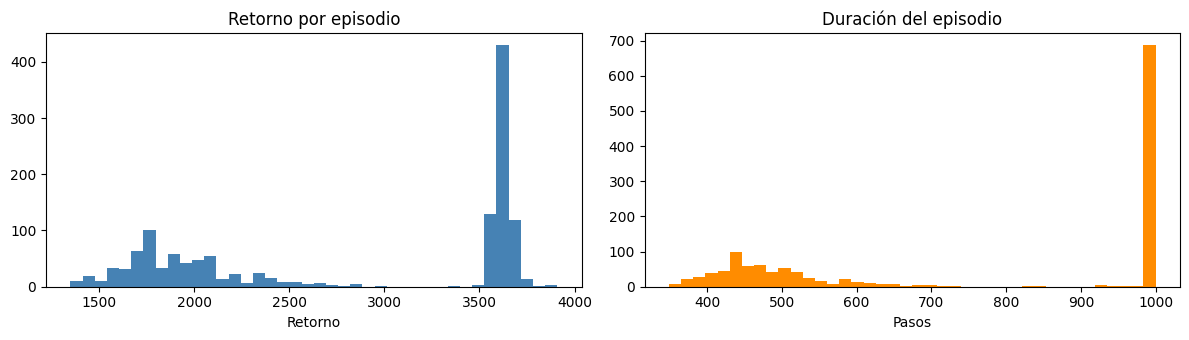

In [5]:
t0 = time.time()
dataset = minari.load_dataset(DATASET_ID, download=True)
print(f"Descarga/carga: {time.time() - t0:.1f} s")
print(f"Episodios: {dataset.total_episodes:,} · Pasos: {dataset.total_steps:,} · Entorno: {dataset.env_spec.id}")

def to_dict(ep):
    # observations trae T+1 estados (incluye el final); se descarta el último
    return dict(obs=ep.observations[:-1].astype(np.float32), act=ep.actions.astype(np.float32),
                rew=ep.rewards.astype(np.float32), term=ep.terminations, trunc=ep.truncations)

episodes = [to_dict(ep) for ep in dataset.iterate_episodes()]
state_dim, act_dim = episodes[0]["obs"].shape[1], episodes[0]["act"].shape[1]
returns = np.array([e["rew"].sum() for e in episodes]); lengths = np.array([len(e["act"]) for e in episodes])
print(f"Dimensión del estado: {state_dim} · Dimensión de la acción: {act_dim}")
print(f"Retorno por episodio: media {returns.mean():.0f}, mín {returns.min():.0f}, máx {returns.max():.0f}")
print(f"Episodios que terminan por caída: {np.mean([e['term'][-1] for e in episodes]):.0%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(returns, bins=40, color="steelblue"); ax[0].set_title("Retorno por episodio"); ax[0].set_xlabel("Retorno")
ax[1].hist(lengths, bins=40, color="darkorange"); ax[1].set_title("Duración del episodio"); ax[1].set_xlabel("Pasos")
plt.tight_layout(); plt.show()

### Partición 90 / 10 por episodios y normalización de estados

In [6]:
perm = rng.permutation(len(episodes))
n_val = int(0.1 * len(episodes))
val_eps   = [episodes[i] for i in perm[:n_val]]
train_eps = [episodes[i] for i in perm[n_val:]]

X_train = np.concatenate([e["obs"] for e in train_eps]); Y_train = np.concatenate([e["act"] for e in train_eps])
X_val   = np.concatenate([e["obs"] for e in val_eps]);   Y_val   = np.concatenate([e["act"] for e in val_eps])
S_MEAN, S_STD = X_train.mean(0), X_train.std(0) + 1e-6
norm = lambda s: (s - S_MEAN) / S_STD
print(f"Entrenamiento: {len(train_eps)} episodios ({len(X_train):,} pasos) · Validación: {len(val_eps)} episodios ({len(X_val):,} pasos)")

Entrenamiento: 1195 episodios (897,508 pasos) · Validación: 132 episodios (101,896 pasos)


## 4. Simulador, evaluación y referencias del puntaje normalizado
Todos los agentes comparten la interfaz `reset()`, `act(obs)` y `update(reward)`, y se evalúan con las mismas semillas.
El puntaje normalizado es $100 \cdot \frac{R - R_{aleatorio}}{R_{experto} - R_{aleatorio}}$.

In [7]:
env = dataset.recover_environment()

def evaluate(agent, n=EVAL_EPISODES, seed0=10_000):
    rets, lens = [], []
    for k in range(n):
        obs, _ = env.reset(seed=seed0 + k); agent.reset(); done, R, L = False, 0.0, 0
        while not done:
            obs, r, term, trunc, _ = env.step(agent.act(obs)); agent.update(r)
            R += r; L += 1; done = term or trunc
        rets.append(R); lens.append(L)
    return np.array(rets), np.array(lens)

class SimpleAgent:
    # Agente sin memoria: la acción depende solo del estado actual
    def __init__(self, fn): self.fn = fn
    def reset(self): pass
    def update(self, r): pass
    def act(self, obs): return np.clip(self.fn(obs), -1, 1)

R_RANDOM = evaluate(SimpleAgent(lambda o: env.action_space.sample()), n=10)[0].mean()
expert = minari.load_dataset(EXPERT_ID, download=True)
R_EXPERT = np.mean([ep.rewards.sum() for ep in expert.iterate_episodes()])
normalized = lambda R: 100 * (R - R_RANDOM) / (R_EXPERT - R_RANDOM)
print(f"Referencia aleatoria: {R_RANDOM:.0f} · Referencia experta (media del dataset expert): {R_EXPERT:.0f}")

metadata.json:   0%|          | 0.00/1.59k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


Dataset mujoco/hopper/expert-v0 downloaded to /root/.minari/datasets/mujoco/hopper/expert-v0
Referencia aleatoria: 19 · Referencia experta (media del dataset expert): 3858


## 5. Modelo tradicional: Behavior Cloning con Random Forest

In [8]:
idx = rng.choice(len(X_train), size=min(RF_SAMPLES, len(X_train)), replace=False)
t0 = time.time()
rf = RandomForestRegressor(n_estimators=RF_TREES, max_depth=20, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
rf.fit(X_train[idx], Y_train[idx])
TIMES["BC · Random Forest"] = time.time() - t0
rf.set_params(n_jobs=1)   # predecir un solo estado es más rápido sin paralelismo
print(f"Entrenamiento: {TIMES['BC · Random Forest']:.1f} s · MSE validación: {np.mean((rf.predict(X_val) - Y_val)**2):.4f}")
rf_agent = SimpleAgent(lambda o: rf.predict(o[None])[0])

Entrenamiento: 33.1 s · MSE validación: 0.0672


## 6. Red neuronal simple: Behavior Cloning con MLP

In [9]:
mlp = nn.Sequential(nn.Linear(state_dim, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(),
                    nn.Linear(256, act_dim), nn.Tanh()).to(DEVICE)
opt = torch.optim.Adam(mlp.parameters(), lr=3e-4)
Xt = torch.tensor(norm(X_train), device=DEVICE); Yt = torch.tensor(Y_train, device=DEVICE)
t0 = time.time()
for step in range(MLP_STEPS):
    b = torch.randint(0, len(Xt), (256,), device=DEVICE)
    loss = ((mlp(Xt[b]) - Yt[b])**2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
TIMES["BC · MLP"] = time.time() - t0
mlp.eval()
with torch.no_grad():
    val_mse = ((mlp(torch.tensor(norm(X_val), device=DEVICE)) - torch.tensor(Y_val, device=DEVICE))**2).mean().item()
print(f"Entrenamiento: {TIMES['BC · MLP']:.1f} s · MSE validación: {val_mse:.4f}")

@torch.no_grad()
def mlp_policy(o): return mlp(torch.tensor(norm(o)[None], dtype=torch.float32, device=DEVICE))[0].cpu().numpy()
mlp_agent = SimpleAgent(mlp_policy)

Entrenamiento: 6.0 s · MSE validación: 0.0759


## 7. RL offline basado en la función Q: Implicit Q-Learning (d3rlpy)
IQL aprende una función Q y una función de valor con la ecuación de Bellman (error TD), y extrae la política
ponderando las acciones del dataset según su ventaja.

In [10]:
cat = lambda key: np.concatenate([e[key] for e in train_eps])
d3_data = d3rlpy.dataset.MDPDataset(
    observations=cat("obs"), actions=cat("act"), rewards=cat("rew"),
    terminals=cat("term").astype(np.float32), timeouts=cat("trunc").astype(np.float32))

iql = d3rlpy.algos.IQLConfig(
    expectile=0.7, weight_temp=3.0, max_weight=100.0,
    observation_scaler=d3rlpy.preprocessing.StandardObservationScaler(),
    reward_scaler=d3rlpy.preprocessing.ReturnBasedRewardScaler(multiplier=1000.0),
).create(device="cuda:0" if DEVICE == "cuda" else "cpu:0")

t0 = time.time()
iql_log = iql.fit(d3_data, n_steps=IQL_STEPS, n_steps_per_epoch=IQL_STEPS, show_progress=False,
                  logger_adapter=d3rlpy.logging.NoopAdapterFactory())
TIMES["IQL (RL offline)"] = time.time() - t0
IQL_STEP_TIME = iql_log[-1][1]["time_step"]   # segundos por paso de actualización (sin la preparación inicial)
print(f"Entrenamiento: {TIMES['IQL (RL offline)']:.1f} s · {IQL_STEP_TIME*1000:.1f} ms por paso")
iql_agent = SimpleAgent(lambda o: iql.predict(o[None].astype(np.float32))[0])

2026-11-21 14:46.32 [info     ] Signatures have been automatically determined. action_signature=Signature(dtype=[dtype('float32')], shape=[(3,)]) observation_signature=Signature(dtype=[dtype('float32')], shape=[(11,)]) reward_signature=Signature(dtype=[dtype('float32')], shape=[(1,)])
2026-11-21 14:46.32 [info     ] Action-space has been automatically determined. action_space=<ActionSpace.CONTINUOUS: 1>
2026-11-21 14:46.32 [info     ] Action size has been automatically determined. action_size=3
2026-11-21 14:46.34 [info     ] dataset info                   dataset_info=DatasetInfo(observation_signature=Signature(dtype=[dtype('float32')], shape=[(11,)]), action_signature=Signature(dtype=[dtype('float32')], shape=[(3,)]), reward_signature=Signature(dtype=[dtype('float32')], shape=[(1,)]), action_space=<ActionSpace.CONTINUOUS: 1>, action_size=3)
2026-11-21 14:46.34 [debug    ] Fitting observation scaler...  observation_scaler=standard
2026-11-21 14:46.45 [debug    ] Fitting reward scaler.

## 8. Decision Transformer (Hugging Face)
Cada trayectoria se convierte en la secuencia $(\hat R_1, s_1, a_1, \hat R_2, s_2, a_2, \dots)$, donde
$\hat R_t = \sum_{t' \ge t} r_{t'}$ es el **retorno restante** (*return-to-go*). Un decoder causal tipo GPT predice
cada acción a partir de los últimos $K$ pasos. Al evaluar se le pide un retorno objetivo, que se va descontando
con las recompensas obtenidas.

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 0), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 0), got 50256. This may result in unexpected behavior.


Parámetros del Decision Transformer: 858,767
paso    600 · pérdida 0.1222 · 9 s
paso   1200 · pérdida 0.0927 · 18 s
paso   1800 · pérdida 0.0824 · 27 s
paso   2400 · pérdida 0.0765 · 35 s
paso   3000 · pérdida 0.0727 · 44 s
MSE validación (acciones): 0.0655


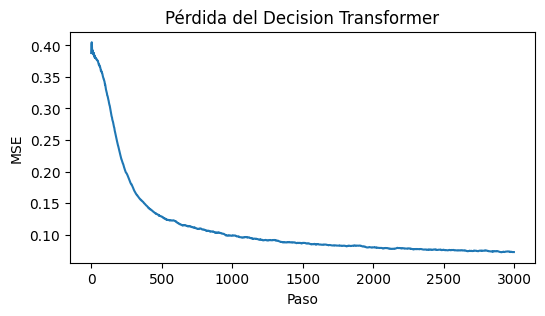

In [11]:
for e in train_eps + val_eps:
    e["rtg"] = np.cumsum(e["rew"][::-1])[::-1].astype(np.float32)   # retorno restante

MAX_EP_LEN = 1000
p_sample = np.array([len(e["act"]) for e in train_eps], dtype=float); p_sample /= p_sample.sum()

def get_batch(eps, batch_size, probs=None):
    # Segmentos de longitud K con relleno a la izquierda y máscara de atención
    s = np.zeros((batch_size, K, state_dim), np.float32); a = np.zeros((batch_size, K, act_dim), np.float32)
    r = np.zeros((batch_size, K, 1), np.float32); g = np.zeros((batch_size, K, 1), np.float32)
    ts = np.zeros((batch_size, K), np.int64); m = np.zeros((batch_size, K), np.float32)
    for b, i in enumerate(rng.choice(len(eps), size=batch_size, p=probs)):
        e = eps[i]; T = len(e["act"]); si = rng.integers(0, T); L = min(K, T - si); sl = slice(si, si + L)
        s[b, K-L:] = norm(e["obs"][sl]); a[b, K-L:] = e["act"][sl]; r[b, K-L:, 0] = e["rew"][sl]
        g[b, K-L:, 0] = e["rtg"][sl] / RTG_SCALE; ts[b, K-L:] = np.arange(si, si + L); m[b, K-L:] = 1
    to = lambda x: torch.tensor(x, device=DEVICE)
    return to(s), to(a), to(r), to(g), to(ts), to(m)

config = DecisionTransformerConfig(state_dim=state_dim, act_dim=act_dim, hidden_size=128, n_layer=3, n_head=1,
                                   n_inner=512, activation_function="relu", max_ep_len=MAX_EP_LEN,
                                   resid_pdrop=0.1, attn_pdrop=0.1, action_tanh=True)
dt = DecisionTransformerModel(config).to(DEVICE)
print(f"Parámetros del Decision Transformer: {sum(p.numel() for p in dt.parameters()):,}")

def dt_loss(batch):
    s, a, r, g, ts, m = batch
    out = dt(states=s, actions=a, rewards=r, returns_to_go=g, timesteps=ts, attention_mask=m, return_dict=True)
    return (((out.action_preds - a)**2).mean(-1) * m).sum() / m.sum()

opt = torch.optim.AdamW(dt.parameters(), lr=1e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda step: min(1.0, (step + 1) / 1000))   # calentamiento
history = []
t0 = time.time()
dt.train()
for step in range(DT_STEPS):
    loss = dt_loss(get_batch(train_eps, BATCH, p_sample))
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(dt.parameters(), 0.25); opt.step(); sched.step()
    history.append(loss.item())
    if (step + 1) % max(1, DT_STEPS // 5) == 0:
        print(f"paso {step+1:>6} · pérdida {np.mean(history[-100:]):.4f} · {time.time()-t0:.0f} s")
TIMES["Decision Transformer"] = time.time() - t0

dt.eval()
with torch.no_grad():
    val_loss = np.mean([dt_loss(get_batch(val_eps, BATCH)).item() for _ in range(20)])
print(f"MSE validación (acciones): {val_loss:.4f}")
plt.figure(figsize=(6, 3)); plt.plot(pd.Series(history).rolling(50, min_periods=1).mean())
plt.title("Pérdida del Decision Transformer"); plt.xlabel("Paso"); plt.ylabel("MSE"); plt.show()

In [12]:
class DTAgent:
    # Genera acciones de forma autorregresiva con los últimos K pasos de historia
    def __init__(self, model, target_return): self.model, self.target = model, target_return
    def reset(self):
        self.S, self.A, self.R = [], [], []; self.G = [self.target / RTG_SCALE]; self.t = 0
    @torch.no_grad()
    def act(self, obs):
        self.S.append(norm(obs)); self.A.append(np.zeros(act_dim, np.float32)); self.R.append(0.0)
        L = min(K, len(self.S)); pad = K - L
        def seq(x, dim):
            x = np.asarray(x[-L:], np.float32).reshape(L, dim)
            return np.concatenate([np.zeros((pad, dim), np.float32), x])
        ts = np.concatenate([np.zeros(pad, np.int64), np.minimum(np.arange(self.t - L + 1, self.t + 1), MAX_EP_LEN - 1)])
        m = np.concatenate([np.zeros(pad), np.ones(L)]).astype(np.float32)
        to = lambda x: torch.tensor(x[None], device=DEVICE)
        out = self.model(states=to(seq(self.S, state_dim)), actions=to(seq(self.A, act_dim)),
                         rewards=to(seq(self.R, 1)), returns_to_go=to(seq(self.G, 1)),
                         timesteps=to(ts), attention_mask=to(m), return_dict=True)
        action = out.action_preds[0, -1].cpu().numpy(); self.A[-1] = action
        return action
    def update(self, r):
        self.R[-1] = r; self.G.append(self.G[-1] - r / RTG_SCALE); self.t += 1

dt_agent = DTAgent(dt, TARGET_RETURN)

## 9. Evaluación comparativa en el simulador

In [13]:
agents = {"Aleatorio": SimpleAgent(lambda o: env.action_space.sample()), "BC · Random Forest": rf_agent,
          "BC · MLP": mlp_agent, "IQL (RL offline)": iql_agent, "Decision Transformer": dt_agent}
rows = []
for name, agent in agents.items():
    t0 = time.time(); rets, lens = evaluate(agent)
    rows.append({"Modelo": name, "Retorno medio": rets.mean(), "Desv.": rets.std(),
                 "Puntaje normalizado": normalized(rets.mean()), "Duración media": lens.mean(),
                 "Entrenamiento (s)": TIMES.get(name, 0.0), "Evaluación (s)": time.time() - t0})
results = pd.DataFrame(rows).set_index("Modelo")
display(results.round(1))
print("Ojo: con estos presupuestos tan cortos los resultados NO son representativos; solo prueban que el flujo funciona.")

,Retorno medio,Desv.,Puntaje normalizado,Duración media,Entrenamiento (s),Evaluación (s)
Modelo,,,,,,
Aleatorio,24.8,12.3,0.2,34.3,0.0,0.0
BC · Random Forest,1075.0,268.2,27.5,304.0,33.1,4.0
BC · MLP,1567.5,11.2,40.3,397.7,6.0,0.8
IQL (RL offline),1436.0,38.1,36.9,371.7,85.7,1.2
Decision Transformer,2079.4,1055.9,53.7,563.0,43.5,7.5


Ojo: con estos presupuestos tan cortos los resultados NO son representativos; solo prueban que el flujo funciona.


### Video corto del Decision Transformer

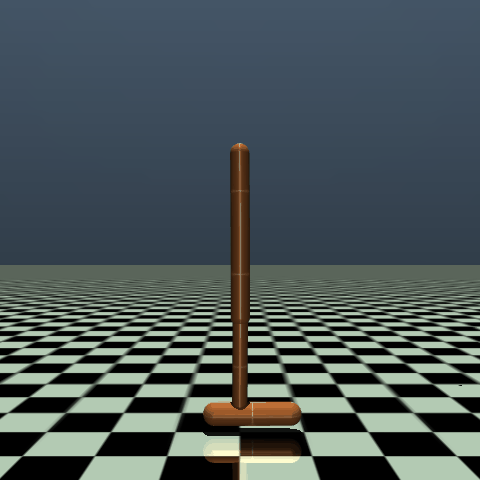

In [14]:
render_env = gym.make(dataset.env_spec, render_mode="rgb_array")
obs, _ = render_env.reset(seed=123); dt_agent.reset(); frames = []
for _ in range(300):
    obs, r, term, trunc, _ = render_env.step(dt_agent.act(obs)); dt_agent.update(r)
    frames.append(render_env.render())
    if term or trunc: break
render_env.close()
imageio.mimsave("dt_hopper.gif", frames[::2], fps=30, loop=0)
display(Image(filename="dt_hopper.gif"))

## 10. Estimación del costo de los experimentos completos

In [15]:
dt_per_1k = TIMES["Decision Transformer"] / DT_STEPS * 1000
iql_per_1k = IQL_STEP_TIME * 1000
print(f"Decision Transformer: {dt_per_1k:.1f} s por cada 1.000 pasos -> 100k pasos ≈ {dt_per_1k*100/60:.0f} min")
print(f"IQL:                  {iql_per_1k:.1f} s por cada 1.000 pasos -> 300k pasos ≈ {iql_per_1k*300/60:.0f} min")

n_runs = 2 * 3 * 3   # 2 robots × 3 calidades de datos × 3 semillas
total_h = n_runs * (dt_per_1k * 100 + iql_per_1k * 300) / 3600
print(f"\nPlan completo ({n_runs} corridas por modelo, sin contar evaluación): ≈ {total_h:.1f} h de GPU")
print("Si la cifra es muy alta, se puede reducir: menos pasos, 1 robot o 2 calidades de datos.")

checklist = {"GPU disponible": DEVICE == "cuda", "Dataset descargado": len(episodes) > 0,
             "Simulador recuperado": env is not None, "Random Forest entrenado": "BC · Random Forest" in TIMES,
             "MLP entrenada": "BC · MLP" in TIMES, "IQL entrenado": "IQL (RL offline)" in TIMES,
             "Decision Transformer entrenado": "Decision Transformer" in TIMES, "Evaluación completa": len(results) == 5}
for k, v in checklist.items(): print(f"{'✅' if v else '❌'} {k}")

Decision Transformer: 14.5 s por cada 1.000 pasos -> 100k pasos ≈ 24 min
IQL:                  14.2 s por cada 1.000 pasos -> 300k pasos ≈ 71 min

Plan completo (18 corridas por modelo, sin contar evaluación): ≈ 28.6 h de GPU
Si la cifra es muy alta, se puede reducir: menos pasos, 1 robot o 2 calidades de datos.
✅ GPU disponible
✅ Dataset descargado
✅ Simulador recuperado
✅ Random Forest entrenado
✅ MLP entrenada
✅ IQL entrenado
✅ Decision Transformer entrenado
✅ Evaluación completa


## Análisis de la prueba

- Todas las etapas funcionaron en Colab (los ✅ de arriba): descarga de datos, simulador, los cuatro modelos y la evaluación.
- Con presupuestos tan cortos (3 000 a 5 000 pasos y 3 episodios) los puntajes no sirven para comparar modelos: el DT sacó 53.7, pero con una desviación de 1 056 en el retorno, y todos los modelos se cayeron antes de los 600 pasos en promedio. Solo confirman que cada modelo aprende algo frente al agente aleatorio (0.2).
- La estimación de costo dio unos 24 minutos por cada DT de 100 000 pasos, lo que se cumplió en los experimentos completos (23 minutos de media). Para IQL se usaron también 100 000 pasos en lugar de 300 000, porque con 300 000 el plan pasaba de 28 horas de GPU.
- Los experimentos completos están en `01_experimentos_completos.ipynb`.